#### 08 · Interpretabilidade dos modelos

Este notebook apresenta somente as explicações necessárias para a entrega da Fase 3:

- quais variáveis sustentam as previsões do modelo de aluno;
- quais variáveis sustentam a previsão do indicador municipal;
- como interpretar uma previsão municipal individual.

Para manter a execução leve e compatível com modelos lineares e de árvore, a medida principal é a **importância por permutação**. O SHAP é opcional e roda em uma amostra pequena apenas quando a biblioteca e o explicador forem compatíveis com o pipeline persistido.

O notebook não retreina modelos.


In [1]:
from pathlib import Path
import os
import sys
import json

import joblib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

SEED = 42


def localizar_raiz(inicio: Path | None = None) -> Path:
    atual = (inicio or Path.cwd()).resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / "data" / "processed").exists() and (candidato / "src").exists():
            return candidato
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


PROJECT_ROOT = localizar_raiz()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
REPORTS = PROJECT_ROOT / "reports"
IMAGES = PROJECT_ROOT / "images"
REPORTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)

from src.modeling.train_models import separar_features, EXCLUIR_ALUNO, EXCLUIR_MUNICIPIO
from src.evaluation.classification_metrics import avaliar_classificacao, avaliar_regressao
from src.visualization.plot_style import aplicar_estilo, salvar_figura, AZUL, LARANJA, CINZA, VERDE, VERMELHO, PALETA
from src.visualization.business_labels import rotulo

aplicar_estilo()
pd.set_option("display.max_columns",100)
pd.set_option("display.width",180)


##### 1. Carregamento dos modelos e metadados


In [2]:
CAMINHOS = {
    "aluno": (MODELS / "modelo_aluno.joblib", MODELS / "modelo_aluno.json"),
    "municipio": (MODELS / "modelo_municipio.joblib", MODELS / "modelo_municipio.json"),
}

for nome,(modelo_path,meta_path) in CAMINHOS.items():
    if not modelo_path.exists() or not meta_path.exists():
        raise FileNotFoundError(f"Artefatos ausentes para {nome}: {modelo_path}, {meta_path}")

modelo_aluno = joblib.load(CAMINHOS["aluno"][0])
modelo_municipio = joblib.load(CAMINHOS["municipio"][0])
meta_aluno = json.loads(CAMINHOS["aluno"][1].read_text(encoding="utf-8"))
meta_municipio = json.loads(CAMINHOS["municipio"][1].read_text(encoding="utf-8"))

print("Modelo aluno:", meta_aluno.get("modelo"))
print("Modelo município:", meta_municipio.get("modelo"))
print("Features aluno:", len(meta_aluno.get("features",[])))
print("Features município:", len(meta_municipio.get("features",[])))


Modelo aluno: logistic_regression
Modelo município: random_forest
Features aluno: 53
Features município: 50


##### 2. Amostra leve da base de alunos


In [3]:
ARQ_ALUNO = PROCESSED / "base_analitica_aluno.parquet"
features_aluno = list(meta_aluno["features"])
colunas_aluno = list(dict.fromkeys(features_aluno + ["ano","alfabetizado","id_municipio"]))

pf = pq.ParquetFile(ARQ_ALUNO)
anos_disponiveis = []
for lote in pf.iter_batches(columns=["ano"], batch_size=100_000, use_threads=False):
    anos_disponiveis.extend(pd.to_numeric(lote.to_pandas()["ano"],errors="coerce").dropna().astype(int).unique())
ANO_ALUNO = max(anos_disponiveis)

partes=[]
limite=5000
for lote in pf.iter_batches(columns=[c for c in colunas_aluno if c in pf.schema.names], batch_size=50_000, use_threads=False):
    df=lote.to_pandas()
    df=df[df["ano"].eq(ANO_ALUNO)].dropna(subset=["alfabetizado"])
    if not df.empty:
        partes.append(df.sample(n=min(500,len(df)),random_state=SEED))
    if sum(len(p) for p in partes)>=limite:
        break

amostra_aluno=pd.concat(partes,ignore_index=True).head(limite)
x_aluno,y_aluno=separar_features(
    amostra_aluno,"alfabetizado",EXCLUIR_ALUNO,colunas_features=features_aluno
)
print(f"Ano explicado: {ANO_ALUNO}; amostra: {len(x_aluno):,}")


Ano explicado: 2025; amostra: 5,000


##### 3. Variáveis mais influentes no modelo de aluno


,variavel,importancia_media,desvio,rotulo
10,nivel_t1,0.0528,0.0031,Nivel de alfabetizacao no ano anterior
1,sigla_uf,0.0096,0.0015,UF
2,rede_codigo,0.0079,0.0003,Codigo da rede
9,indicador_t1,0.0064,0.0007,Alfabetizados no ano anterior (%)
37,media_inse,0.0054,0.0014,Nivel socioeconomico medio (INSE)
52,participacao_vab_adm_publica_pct,0.0048,0.0006,Participacao da administracao publica no PIB (%)
40,pc_nivel_2,0.0039,0.0001,Alunos no nivel socioeconomico 2 (%)
24,ideb_ideb_observado_anterior,0.0031,0.0012,IDEB anterior
51,participacao_vab_servicos_pct,0.0030,0.0017,Participacao dos servicos no PIB (%)
13,salto_necessario,0.0028,0.0005,Avanco necessario para atingir a meta (p.p.)


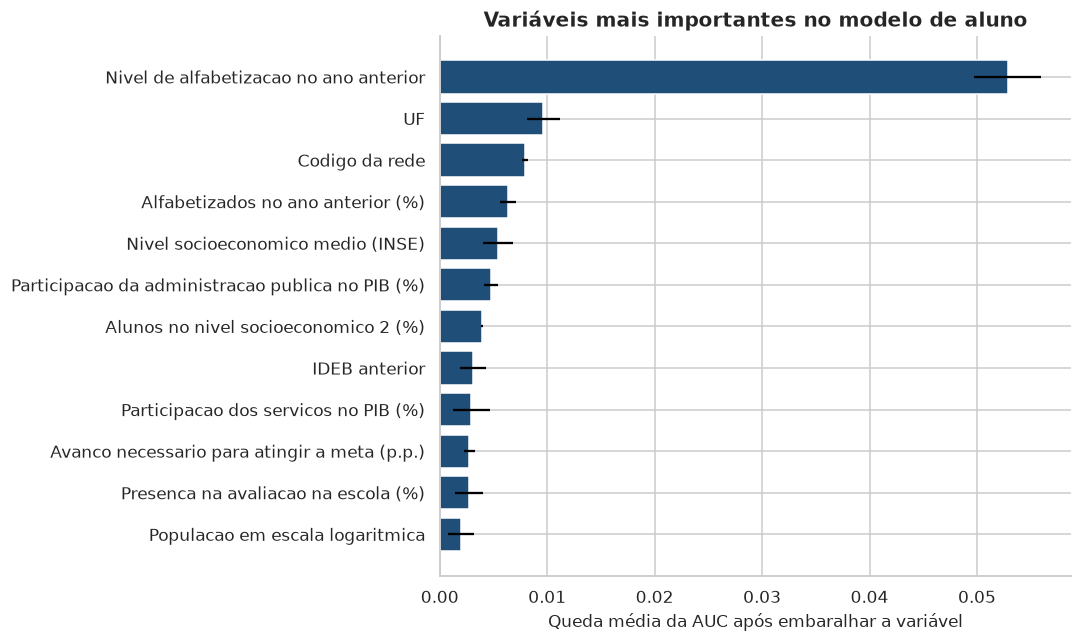

In [4]:
perm_aluno = permutation_importance(
    modelo_aluno,
    x_aluno,
    y_aluno.astype(int),
    scoring="roc_auc",
    n_repeats=3,
    random_state=SEED,
    n_jobs=1,
)
imp_aluno = pd.DataFrame({
    "variavel": x_aluno.columns,
    "importancia_media": perm_aluno.importances_mean,
    "desvio": perm_aluno.importances_std,
}).sort_values("importancia_media",ascending=False)
imp_aluno["rotulo"] = imp_aluno["variavel"].map(rotulo)
imp_aluno.to_csv(REPORTS / "importancia_permutacao_aluno.csv", index=False)
display(imp_aluno.head(15).round(4))

fig,ax=plt.subplots(figsize=(10,6))
top=imp_aluno.head(12).sort_values("importancia_media")
ax.barh(top["rotulo"],top["importancia_media"],xerr=top["desvio"],color=AZUL)
ax.set_xlabel("Queda média da AUC após embaralhar a variável")
ax.set_title("Variáveis mais importantes no modelo de aluno")
salvar_figura(fig,"08_importancia_modelo_aluno")
plt.show()


##### 4. Variáveis mais influentes no modelo municipal


,variavel,aumento_erro_medio,desvio,rotulo
7,nivel_t1,12.0498,0.1545,Nivel de alfabetizacao no ano anterior
6,indicador_t1,0.4819,0.0106,Alfabetizados no ano anterior (%)
12,ideb_ideb_observado_ultimo,0.1642,0.0093,IDEB mais recente
10,salto_necessario,0.1323,0.0064,Avanco necessario para atingir a meta (p.p.)
9,meta_t,0.1228,0.0062,Meta do ano-alvo (%)
8,participacao_t1,0.1142,0.0046,Participacao na avaliacao anterior (%)
14,ideb_ideb_nota_matematica_ultimo,0.0578,0.0039,Nota de Matematica mais recente
13,ideb_ideb_nota_portugues_ultimo,0.0510,0.0053,Nota de Portugues mais recente
15,ideb_ideb_nota_media_ultimo,0.0488,0.0027,Nota media mais recente
46,participacao_vab_agro_pct,0.0404,0.0029,Participacao da agropecuaria no PIB (%)


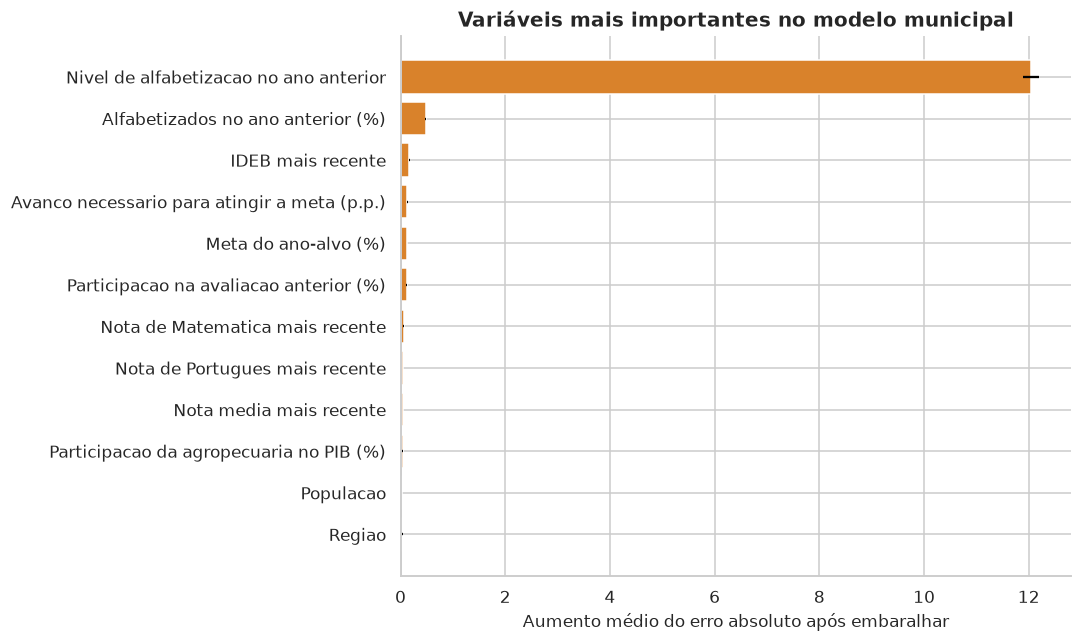

In [5]:
ARQ_MUN = PROCESSED / "base_analitica_municipio.parquet"
abt_mun = pd.read_parquet(ARQ_MUN)
anos_observados = sorted(pd.to_numeric(abt_mun.loc[abt_mun["indicador_t"].notna(),"ano_alvo"],errors="coerce").dropna().astype(int).unique())
ANO_MUN = anos_observados[-1]
base_mun = abt_mun[abt_mun["ano_alvo"].eq(ANO_MUN)].copy()
features_mun = list(meta_municipio["features"])
x_mun,y_mun = separar_features(
    base_mun,"indicador_t",EXCLUIR_MUNICIPIO,colunas_features=features_mun
)

perm_mun = permutation_importance(
    modelo_municipio,
    x_mun,
    y_mun.astype(float),
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=SEED,
    n_jobs=1,
)
imp_mun = pd.DataFrame({
    "variavel": x_mun.columns,
    "aumento_erro_medio": perm_mun.importances_mean,
    "desvio": perm_mun.importances_std,
}).sort_values("aumento_erro_medio",ascending=False)
imp_mun["rotulo"] = imp_mun["variavel"].map(rotulo)
imp_mun.to_csv(REPORTS / "importancia_permutacao_municipio.csv", index=False)
display(imp_mun.head(15).round(4))

fig,ax=plt.subplots(figsize=(10,6))
top=imp_mun.head(12).sort_values("aumento_erro_medio")
ax.barh(top["rotulo"],top["aumento_erro_medio"],xerr=top["desvio"],color=LARANJA)
ax.set_xlabel("Aumento médio do erro absoluto após embaralhar")
ax.set_title("Variáveis mais importantes no modelo municipal")
salvar_figura(fig,"08_importancia_modelo_municipal")
plt.show()


##### 5. Explicação local de um município prioritário


In [6]:
arquivos_risco = sorted(REPORTS.glob("municipios_risco_*.csv"))
if not arquivos_risco:
    print("Relatório de risco não encontrado. A explicação local foi ignorada.")
else:
    ranking=pd.read_csv(arquivos_risco[-1],dtype={"id_municipio":"string"})
    coluna_risco=next((c for c in ["risco_nao_atingir","risco_2026","risco"] if c in ranking.columns),None)
    if coluna_risco is None:
        raise KeyError("O relatório não possui coluna de risco reconhecida.")
    alvo=ranking.sort_values(coluna_risco,ascending=False).iloc[0]
    id_alvo=str(alvo["id_municipio"]).replace(".0","").zfill(7)
    base_mun["id_municipio_txt"]=base_mun["id_municipio"].astype("string").str.replace(r"\.0$","",regex=True).str.zfill(7)
    linha=base_mun[base_mun["id_municipio_txt"].eq(id_alvo)]
    if linha.empty:
        print("Município prioritário não localizado no último ano observado.")
    else:
        valores=[]
        for _,r in imp_mun.head(8).iterrows():
            v=r["variavel"]
            valores.append({"variavel":r["rotulo"],"valor_municipio":linha.iloc[0].get(v,np.nan),"mediana_nacional":base_mun[v].median()})
        explicacao_local=pd.DataFrame(valores)
        display(alvo.to_frame("valor"))
        display(explicacao_local.round(3))


,valor
posicao,1
ano_alvo,2026
id_municipio,4310553
nome_municipio,Itacurubi
sigla_uf,RS
rede,municipal
indicador_t1,21.0
meta_t,80.0
indicador_previsto,38.319646
folga_prevista_pp,-41.680354


,variavel,valor_municipio,mediana_nacional
0,Nivel de alfabetizacao no ano anterior,<NA>,4.000
1,Alfabetizados no ano anterior (%),<NA>,64.000
2,IDEB mais recente,5.2,5.800
3,Avanco necessario para atingir a meta (p.p.),<NA>,2.000
4,Meta do ano-alvo (%),80.0,67.000
5,Participacao na avaliacao anterior (%),<NA>,94.000
6,Nota de Matematica mais recente,201.13,220.710
7,Nota de Portugues mais recente,190.39,209.375


#### Resumo do Notebook 08 · Interpretabilidade dos Modelos

O notebook usa **importância por permutação** para medir quanto o desempenho piora quando cada variável é embaralhada. A análise mostra dependência do modelo, não efeito causal. citeturn110search15

#### Modelo de aluno

No gráfico, a variável dominante é **nível de alfabetização no ano anterior**, cuja permutação reduz a AUC em aproximadamente **0,053**. UF aparece em segundo lugar, perto de **0,010**, seguida de código da rede e percentual de alfabetizados no ano anterior, ambos abaixo de **0,010**. As demais variáveis apresentam quedas individuais pequenas, em geral inferiores a **0,006**. citeturn110search15

O gráfico mostra grande concentração de importância no histórico local. UF e rede acrescentam sinal contextual, enquanto INSE, composição econômica, IDEB anterior, avanço necessário, presença na avaliação e população têm contribuições menores. As barras de erro são pequenas na variável principal e não alteram a liderança do histórico.

#### Modelo municipal

A variável **nível de alfabetização no ano anterior** domina o gráfico: o erro absoluto aumenta em cerca de **12 pontos percentuais** quando essa informação é embaralhada. A segunda variável fica abaixo de **0,5 p.p.**, e as demais apresentam aumentos próximos de zero na escala do gráfico. citeturn110search15

Esse resultado indica que o modelo municipal depende quase totalmente da trajetória passada para prever o nível atual. IDEB, meta, avanço necessário, participação anterior, notas, população e região acrescentam sinal complementar, mas muito menor.

#### Explicação local destacada

O município prioritário apresentado no notebook tem:

- indicador previsto de **38,3%**;
- meta de **80,0%**;
- folga prevista de **-41,7 p.p.**;
- risco de não atingir a meta de aproximadamente **99,8%**. citeturn110search15

#### Conclusões

- Os dois modelos dependem fortemente do **histórico de alfabetização**.
- No modelo de aluno, UF e rede ainda possuem relevância contextual, mas ficam muito abaixo da variável principal.
- No modelo municipal, uma única variável histórica concentra quase toda a importância por permutação.
- O risco municipal não é previsto diretamente: o modelo estima o nível e depois compara a previsão com a meta.
- Importância elevada não prova causalidade. A análise informa de quais variáveis o modelo depende.
- A concentração em uma única feature reforça a necessidade de comparar o modelo com uma regra simples baseada no resultado anterior e monitorar mudanças entre anos.

> **Síntese:** o resultado futuro é explicado principalmente pelo desempenho passado do próprio território. As demais variáveis refinam a previsão, mas têm contribuição individual muito menor, sobretudo no modelo municipal. citeturn110search15
